In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
import sklearn

In [11]:
from sklearn.datasets import load_diabetes
data = load_diabetes(as_frame=True)
diab = data.frame          # 10 features + "target"
diab.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [12]:
diab.describe()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.268604e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


In [14]:
correlation =diab.corr(numeric_only=True)

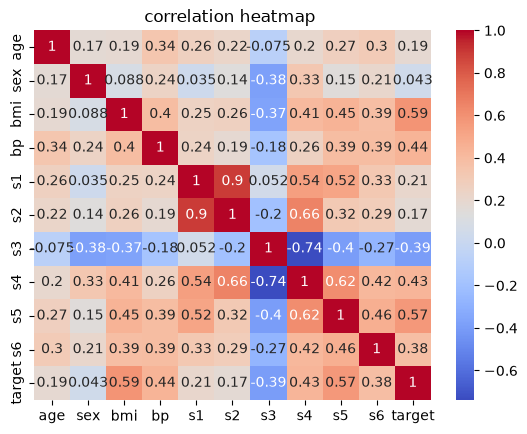

In [15]:
plt.Figure(figsize=(10,8))
sns.heatmap(correlation,annot=True,cmap="coolwarm")
plt.title("correlation heatmap ")
plt.show()

In [18]:
target_corr=correlation["target"].drop("target")
top_3= target_corr.sort_values(key=abs,ascending=False).head(3)
print(top_3)

bmi    0.586450
s5     0.565883
bp     0.441482
Name: target, dtype: float64


In [19]:
from sklearn.model_selection import train_test_split

In [22]:
x=diab.drop("target",axis=1)
y=diab["target"]

In [31]:
x_train,x_test,y_train,y_test = train_test_split(
x,
y,
test_size=0.20,
random_state=42
)
print("training data:",x_train.shape)
print("testing data:",x_test.shape)


training data: (353, 10)
testing data: (89, 10)


In [ ]:
##Train Simple LR on the single best feature, then Multiple LR on all features. Report MAE, RMSE, R².

In [32]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [36]:
x_train_bmi=x_train[["bmi"]]
x_test_bmi=x_test[["bmi"]]
simple_lr=LinearRegression()
simple_lr.fit(x_train_bmi,y_train)
y_predict_simple=simple_lr.predict(x_test_bmi)

In [48]:
mae_simple=mean_absolute_error(
    y_test,
    y_predict_simple

)
print("mae:",mae_simple)

mae: 52.25997644534553


In [49]:
rmsc_simple=mean_squared_error(
    y_test,
    y_predict_simple
)
print("rmse:",rmsc_simple)

rmse: 4061.8259284949268


In [47]:
r2_simple=r2_score(
    y_test,
    y_predict_simple
)
print("r2:", r2_score)

r2: <function r2_score at 0x00000225594CFCC0>


In [ ]:
###ridge,lasso##
##Train Ridge and Lasso for alphas [0.01, 0.1, 1, 10]. Which features does Lasso drop as alpha grows?

In [ ]:
##ridge



In [56]:
from sklearn.linear_model import Ridge,Lasso

In [75]:
ridge = Ridge(alpha=1.0).fit(x_train, y_train)
lasso = Lasso(alpha=2.0).fit(x_train, y_train)
lr_model=LinearRegression().fit(x_train,y_train)
pd.DataFrame({"Linear": lr_model.coef_, "Ridge": ridge.coef_, "Lasso": lasso.coef_}, index=x_train.columns).round(3)


     

,Linear,Ridge,Lasso
age,37.904,45.367,0.000
sex,-241.964,-76.666,0.000
bmi,542.429,291.339,101.162
bp,347.704,198.996,0.000
s1,-931.489,-0.530,0.000
s2,518.062,-28.577,0.000
s3,163.420,-144.512,0.000
s4,275.318,119.260,0.000
s5,736.199,230.222,0.000
s6,48.671,112.150,0.000


In [73]:
for alpha in alphas:

    lasso = Lasso(alpha=alpha, max_iter=10000)

    lasso.fit(x_train, y_train)

    print("\nAlpha:", alpha)

    for feature, coefficient in zip(x_train.columns, lasso.coef_):
        print(feature, ":", coefficient)


Alpha: 0.01
age : 35.34745132624424
sex : -231.90666401475264
bmi : 551.3032416036383
bp : 341.31346894855585
s1 : -483.56713972338235
s2 : 165.9905316400414
s3 : -25.834899104469397
s4 : 216.87580275855453
s5 : 566.8150033624479
s6 : 49.702474766483604

Alpha: 0.1
age : 0.0
sex : -152.66477923425137
bmi : 552.6977752929223
bp : 303.3651579067187
s1 : -81.36500663537602
s2 : -0.0
s3 : -229.25577638583206
s4 : 0.0
s5 : 447.91952518413854
s6 : 29.642617038207664

Alpha: 1
age : 0.0
sex : -0.0
bmi : 413.4318479231422
bp : 34.830515180609794
s1 : 0.0
s2 : 0.0
s3 : -0.0
s4 : 0.0
s5 : 258.15289363124595
s6 : 0.0

Alpha: 10
age : 0.0
sex : 0.0
bmi : 0.0
bp : 0.0
s1 : 0.0
s2 : 0.0
s3 : 0.0
s4 : 0.0
s5 : 0.0
s6 : 0.0


In [74]:
for alpha in alphas:

    lasso = Lasso(alpha=alpha, max_iter=10000)
    lasso.fit(x_train, y_train)

    dropped = x_train.columns[lasso.coef_ == 0].tolist()

    print("Alpha:", alpha)
    print("Dropped features:", dropped)

Alpha: 0.01
Dropped features: []
Alpha: 0.1
Dropped features: ['age', 's2', 's4']
Alpha: 1
Dropped features: ['age', 'sex', 's1', 's2', 's3', 's4', 's6']
Alpha: 10
Dropped features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


In [ ]:
###model comparision##

In [57]:
def evaluate(name, model, Xtr=x_train, Xte=x_test):
    model.fit(Xtr, y_train)
    p = model.predict(Xte)
    return {"Model": name,
            "Train R2": model.score(Xtr, y_train),
            "MAE": mean_absolute_error(y_test, p),
            "RMSE": np.sqrt(mean_squared_error(y_test, p)),
            "R2": r2_score(y_test, p)}

results = pd.DataFrame([
    evaluate("Simple LR (bmi)", LinearRegression(), x_train[["bmi"]], x_test[["bmi"]]),
    evaluate("Multiple LR", LinearRegression()),
    evaluate("Ridge (alpha=1)", Ridge(alpha=1.0)),
    evaluate("Lasso (alpha=2)", Lasso(alpha=2.0)),
]).set_index("Model").round(3)
results

,Train R2,MAE,RMSE,R2
Model,,,,
Simple LR (bmi),0.366,52.260,63.732,0.233
Multiple LR,0.528,42.794,53.853,0.453
Ridge (alpha=1),0.442,46.139,55.474,0.419
Lasso (alpha=2),0.070,62.097,70.788,0.054
